In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
df = pd.read_csv(r"transformed_retail_sales.csv")
df.head()

,Order_ID,Order_Date,Ship_Date,Ship_Mode,Customer_ID,Customer_Name,Market_Segment,Region,State,City,...,Month_Name,Quarter,Profit_Margin,Order_Value,Customer_Segment,Sales_Category,Profit_Category,Order_Size,Discount_Band,Product_Performance
0,ORD-2023-00001,1680,02-01-2023,First Class,C-0070,Kavita Banerjee,Consumer,West,Rajasthan,Jaipur,...,January,1,26.101867,1680,High Value,Medium Sales,Low Profit,Small Order,Low Discount,Average Performer
1,ORD-2023-00001,8980,02-01-2023,First Class,C-0070,Kavita Banerjee,Consumer,West,Rajasthan,Jaipur,...,January,1,8.599029,8980,High Value,High Sales,Low Profit,Small Order,High Discount,High Performer
2,ORD-2023-00002,5400,01-01-2023,Same Day,C-0016,Neha Joshi,Consumer,Central,Madhya Pradesh,Bhopal,...,January,1,38.605000,5400,High Value,High Sales,High Profit,Large Order,No Discount,High Performer
3,ORD-2023-00002,3230,01-01-2023,Same Day,C-0016,Neha Joshi,Consumer,Central,Madhya Pradesh,Bhopal,...,January,1,18.975395,3230,High Value,Medium Sales,Low Profit,Small Order,Low Discount,Average Performer
4,ORD-2023-00002,1600,01-01-2023,Same Day,C-0016,Neha Joshi,Consumer,Central,Madhya Pradesh,Bhopal,...,January,1,29.865625,1600,High Value,Medium Sales,Low Profit,Medium Order,No Discount,Average Performer


In [9]:
df.shape

(9872, 31)

In [10]:
# Calculate total sales
df["Sales"].sum()

np.float64(127131397.7)

In [11]:
#Store the result in a variable
total_sales = df["Sales"].sum()
print("Total Sales:", total_sales)

Total Sales: 127131397.7


In [12]:
#Monthly Sales Analysis
monthly_sales = df.groupby("Month_Name")["Sales"].sum()
print(monthly_sales)

Month_Name
April        10440211.3
August       11258485.8
December     13076538.2
February      7540877.0
January       9253859.8
July         10673296.1
June          8855295.0
March         9269952.1
May           9267695.0
November     16073708.7
October      11267835.8
September    10153642.9
Name: Sales, dtype: float64


In [13]:
#Arrange months in calendar order
month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

monthly_sales = monthly_sales.reindex(month_order)
print(monthly_sales)

Month_Name
January       9253859.8
February      7540877.0
March         9269952.1
April        10440211.3
May           9267695.0
June          8855295.0
July         10673296.1
August       11258485.8
September    10153642.9
October      11267835.8
November     16073708.7
December     13076538.2
Name: Sales, dtype: float64


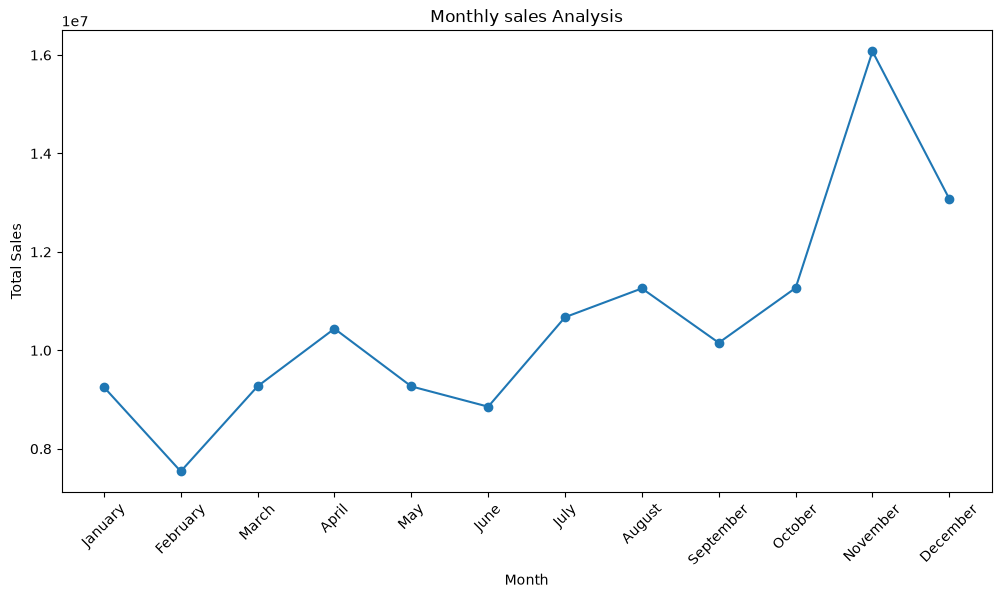

In [14]:
# Monthly Sales Line Chart
plt.figure(figsize=(12,6))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o")

plt.title("Monthly sales Analysis")
plt.xlabel("Month")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)
plt.show()

In [15]:
#Category Sales Analysis
category_Sales = df.groupby("Category")["Sales"].sum()
print(category_Sales)

Category
Furniture          27624845.8
Office Supplies    28322948.5
Technology         71183603.4
Name: Sales, dtype: float64


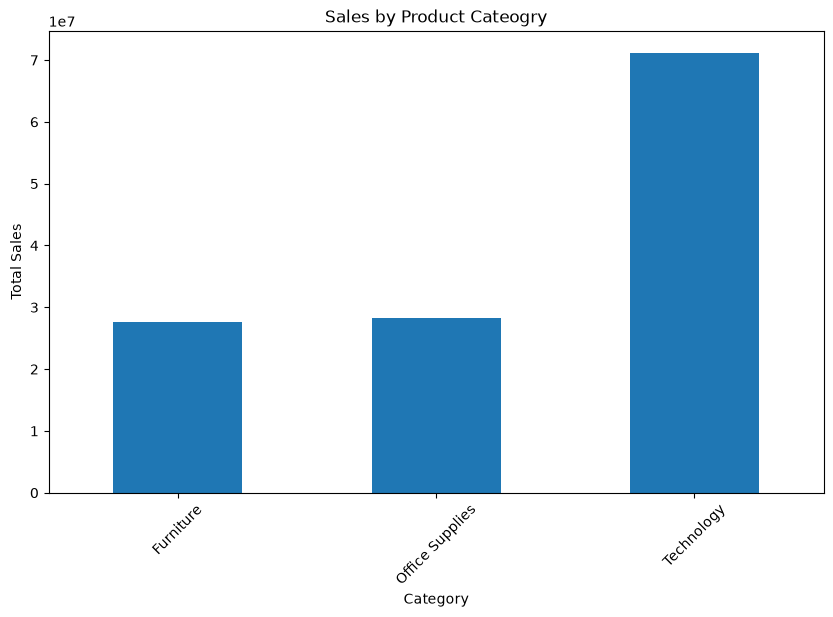

In [16]:
# Creating a bar chart
plt.figure(figsize=(10,6))
category_Sales.plot(kind="bar")

plt.title("Sales by Product Cateogry")
plt.xlabel("Category")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)
plt.show()

In [17]:
# Analyze total sales generated by each region.
region_sales = df.groupby("Region")["Sales"].sum()
print(region_sales)

Region
Central    14088584.0
East       12390361.5
North      30506413.5
South      36710245.0
West       33435793.7
Name: Sales, dtype: float64


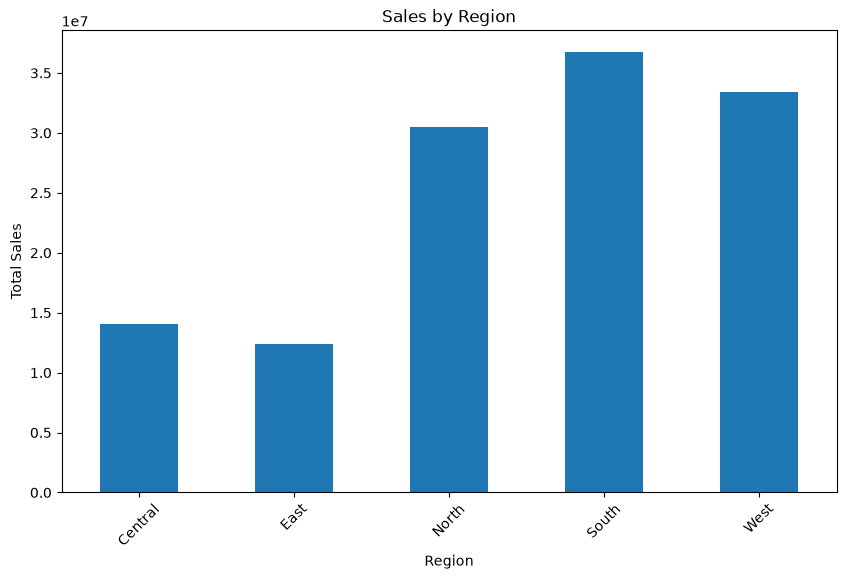

In [18]:
plt.figure(figsize=(10,6))
region_sales.plot(kind="bar")

plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)
plt.show()


In [19]:
#Top 10 and Bottom 10 products based on total sales.
product_sales = df.groupby("Product_Name")["Sales"].sum()
print(product_sales)


Product_Name
Basic Accessory       101671.5
Basic Appliance      1540819.8
Basic Art Kit         203731.0
Basic Binder          658825.2
Basic Bookcase        455526.4
                       ...    
Smart Paper Ream      380325.0
Smart Phone          3480213.0
Smart Storage Box     777670.4
Smart Supply Kit      371154.2
Smart Table           891730.2
Name: Sales, Length: 136, dtype: float64


In [20]:
top_10_products = product_sales.sort_values(ascending=False).head(10)
print(top_10_products)

Product_Name
Pro Phone            8471628.0
Premium Phone        6113703.6
Eco Phone            5665779.6
Classic Copier       4548146.4
Deluxe Phone         4311218.5
Eco Copier           4172747.4
Premium Appliance    3554290.0
Smart Phone          3480213.0
Pro Copier           3285499.2
Classic Chair        2822027.7
Name: Sales, dtype: float64


In [21]:
bottom_10_products = product_sales.sort_values(ascending=True).head(10)
print(bottom_10_products)

Product_Name
Smart Fastener Pack      3270.4
Pro Label Pack           6832.8
Compact Label Pack      12550.8
Deluxe Label Pack       17775.9
Basic Label Pack        18760.5
Pro Fastener Pack       22916.0
Eco Fastener Pack       26992.0
Deluxe Fastener Pack    27724.8
Smart Art Kit           28896.0
Basic Furnishing Set    29318.1
Name: Sales, dtype: float64


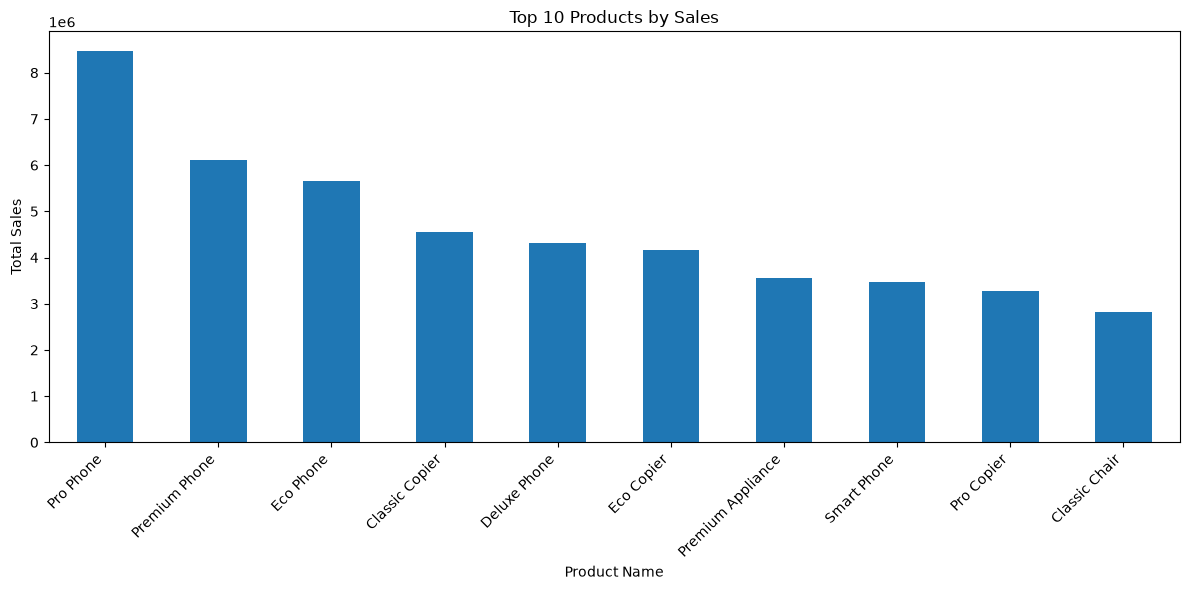

In [22]:
#Top 10 Products Bar Chart
plt.figure(figsize=(12, 6))
top_10_products.plot(kind="bar")

plt.title("Top 10 Products by Sales")
plt.xlabel("Product Name")
plt.ylabel("Total Sales")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

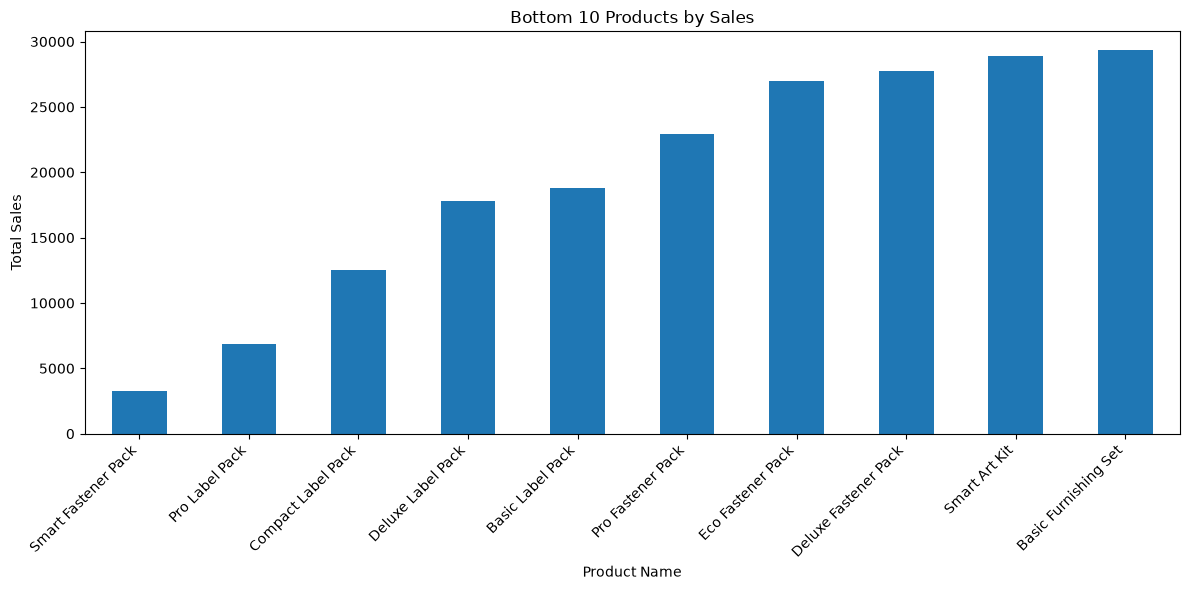

In [23]:
#Top 10 Products Bar Chart
plt.figure(figsize=(12, 6))

bottom_10_products.plot(kind="bar")

plt.title("Bottom 10 Products by Sales")
plt.xlabel("Product Name")
plt.ylabel("Total Sales")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()

In [25]:
#Calculate total profit
total_profit = df["Profit"].sum()
print("Total profit:", total_profit)

Total profit: 16428487.74


In [29]:
#Calculate category-wise profit
category_profit = df.groupby("Category")["Profit"].sum()
print(category_profit)

Category
Furniture            -10236.60
Office Supplies     5411199.67
Technology         11027524.67
Name: Profit, dtype: float64


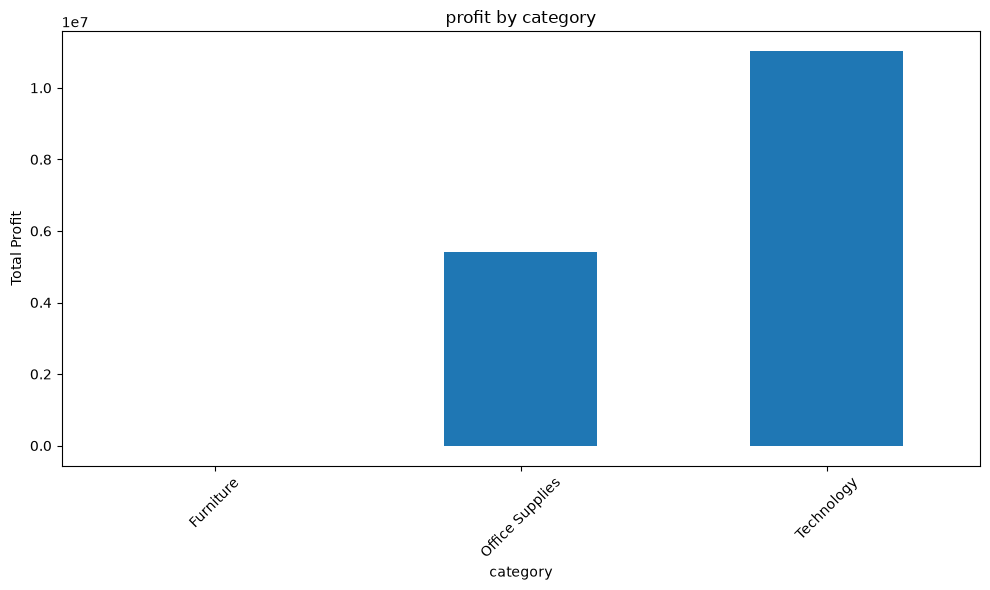

In [31]:
# Create a bar chart
plt.figure(figsize=(10,6))
category_profit.plot(kind="bar")

plt.title("profit by category")
plt.xlabel("category")
plt.ylabel("Total Profit")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [32]:
#Calculate regional profit
region_profit = df.groupby("Region")["Profit"].sum()
print(region_profit)


Region
Central    1883195.03
East       1694751.39
North      4195931.27
South      4994283.91
West       3660326.14
Name: Profit, dtype: float64


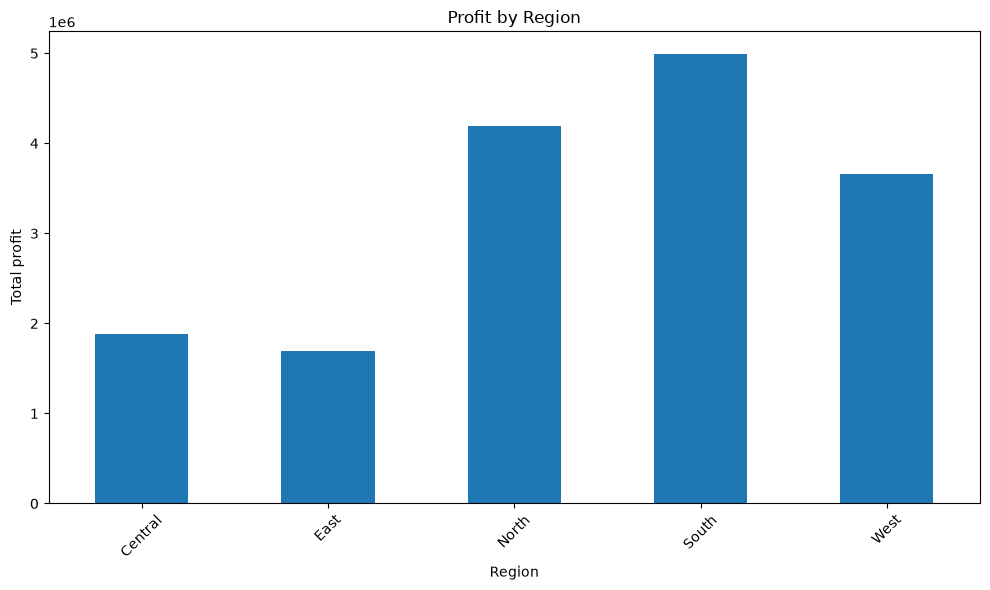

In [34]:
#Create a bar chart
plt.figure(figsize=(10,6))
region_profit.plot(kind="bar")

plt.title("Profit by Region")
plt.xlabel("Region")
plt.ylabel("Total profit")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()


In [37]:
#Calculate product-wise profit
product_profit = df.groupby("Product_Name")["Profit"].sum()
print(product_profit)


Product_Name
Basic Accessory       27801.93
Basic Appliance      337400.01
Basic Art Kit         49798.04
Basic Binder         192174.60
Basic Bookcase       -69208.97
                       ...    
Smart Paper Ream     108341.24
Smart Phone          654622.65
Smart Storage Box     99835.89
Smart Supply Kit     -31770.74
Smart Table         -173153.57
Name: Profit, Length: 136, dtype: float64


In [38]:
top_10_profit = product_profit.sort_values(
    ascending=False
).head(10)
print(top_10_profit)

Product_Name
Classic Copier       1255336.26
Pro Phone            1165500.03
Eco Copier           1159018.84
Premium Phone        1068127.44
Eco Phone            1031802.38
Pro Copier           1002797.33
Premium Appliance     673492.99
Deluxe Phone          662041.95
Smart Phone           654622.65
Premium Accessory     622355.15
Name: Profit, dtype: float64


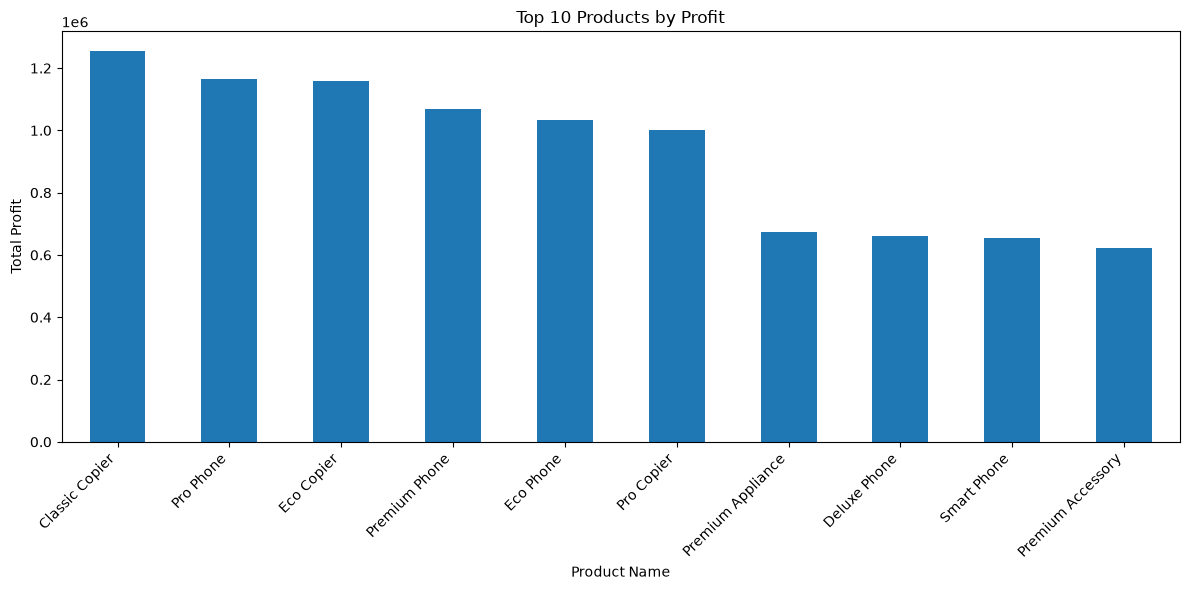

In [39]:
#Create a bar chart
plt.figure(figsize=(12, 6))

top_10_profit.plot(kind="bar")

plt.title("Top 10 Products by Profit")
plt.xlabel("Product Name")
plt.ylabel("Total Profit")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()

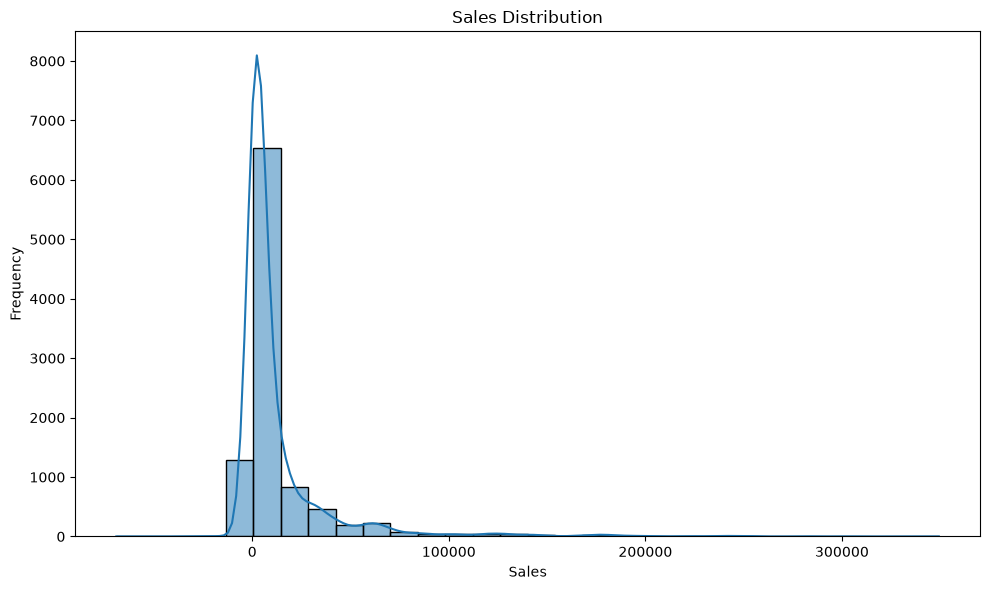

In [41]:
#Create the Sales Distribution Histogram
plt.figure(figsize=(10, 6))
sns.histplot(df["Sales"], bins=30, kde=True)

plt.title("Sales Distribution")
plt.xlabel("Sales")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

DAY 26 — CUSTOMER ANALYSIS


In [44]:
#Calculate total sales for each customer.
customer_sales = df.groupby("Customer_ID")["Sales"].sum()
print(customer_sales)

Customer_ID
C-0001     11218.0
C-0002     68821.0
C-0003    951225.0
C-0004    117333.5
C-0005    341270.0
            ...   
C-0991    273807.0
C-0993    331101.5
C-0995      7630.0
C-0996     87175.5
C-0997    667800.0
Name: Sales, Length: 754, dtype: float64


In [45]:
#Identify the customers who generate the highest sales.
top_10_customers = customer_sales.sort_values(ascending=False).head(10)

print("Top 10 Customers:")
print(top_10_customers)

Top 10 Customers:
Customer_ID
C-0930    2943695.0
C-0787    2628185.0
C-0080    2488019.5
C-0120    2128846.0
C-0074    1996114.7
C-0016    1666500.5
C-0391    1634280.0
C-0396    1405063.0
C-0488    1265093.5
C-0923    1112704.5
Name: Sales, dtype: float64


In [46]:
top_20_customers = customer_sales.sort_values(ascending=False).head(20)

print("Top 20 Customers:")
print(top_20_customers)

Top 20 Customers:
Customer_ID
C-0930    2943695.0
C-0787    2628185.0
C-0080    2488019.5
C-0120    2128846.0
C-0074    1996114.7
C-0016    1666500.5
C-0391    1634280.0
C-0396    1405063.0
C-0488    1265093.5
C-0923    1112704.5
C-0036    1098302.5
C-0659    1057520.0
C-0172    1050339.0
C-0003     951225.0
C-0449     934138.0
C-0942     932592.8
C-0050     871702.5
C-0108     826816.0
C-0901     820829.5
C-0012     808848.5
Name: Sales, dtype: float64


In [47]:
#Calculate the average sales generated per customer
average_customer_spending = customer_sales.sum() / customer_sales.count()
print("Average Customer Spending:", average_customer_spending)

Average Customer Spending: 168609.28076923077


In [48]:
#Identify customers who have placed more than one order
order_per_customer = df.groupby("Customer_ID")["Order_ID"].nunique()
print(order_per_customer)

Customer_ID
C-0001     4
C-0002     3
C-0003    23
C-0004    11
C-0005    11
          ..
C-0991     5
C-0993     3
C-0995     2
C-0996     3
C-0997    20
Name: Order_ID, Length: 754, dtype: int64


In [53]:
#Identify Repeat Customers
repeat_customer = order_per_customer[order_per_customer > 1]

print("Repeat Customer:")
print(repeat_customer)
print("Total Repeat Customers:", len(repeat_customer))

Repeat Customer:
Customer_ID
C-0001     4
C-0002     3
C-0003    23
C-0004    11
C-0005    11
          ..
C-0991     5
C-0993     3
C-0995     2
C-0996     3
C-0997    20
Name: Order_ID, Length: 567, dtype: int64
Total Repeat Customers: 567


In [57]:
#Calculate each customer's percentage contribution to total sales
customer_contribution = (customer_sales / customer_sales.sum()) * 100
print(customer_contribution)

Customer_ID
C-0001    0.008824
C-0002    0.054134
C-0003    0.748222
C-0004    0.092293
C-0005    0.268439
            ...   
C-0991    0.215373
C-0993    0.260440
C-0995    0.006002
C-0996    0.068571
C-0997    0.525283
Name: Sales, Length: 754, dtype: float64


In [58]:
#Display Top 10 Customers by Contribution
top_10_contribution = customer_contribution.sort_values(ascending=False)
print(top_10_contribution)

Customer_ID
C-0930    2.315474
C-0787    2.067298
C-0080    1.957046
C-0120    1.674524
C-0074    1.570119
            ...   
C-0801    0.000315
C-0556    0.000142
C-0251    0.000126
C-0302    0.000120
C-0369    0.000080
Name: Sales, Length: 754, dtype: float64


In [62]:
# Customer Segments
# Divide customers into three groups based on their total sales.

# High Value: Sales ≥ ₹50,000
# Medium Value: Sales ≥ ₹20,000 and < ₹50,000
# Low Value: Sales < ₹20,000

customer_segments = pd.cut(  # pd.cut() — Divides customer sales into groups.
    customer_sales,
    bins=[-float ("inf"), 20000, 50000, float("inf")], # bins — Defines the sales boundaries.
    labels=["Low Value", "Medium Value", "High Value"] # labels — Assigns a name to each group
)
print(customer_segments)
print(customer_segments.value_counts())

Customer_ID
C-0001     Low Value
C-0002    High Value
C-0003    High Value
C-0004    High Value
C-0005    High Value
             ...    
C-0991    High Value
C-0993    High Value
C-0995     Low Value
C-0996    High Value
C-0997    High Value
Name: Sales, Length: 754, dtype: category
Categories (3, object): ['Low Value' < 'Medium Value' < 'High Value']
Sales
High Value      474
Low Value       181
Medium Value     99
Name: count, dtype: int64


In [63]:
#Add Segments to Your DataFrame
df["Customer_Segment"] = df["Customer_ID"].map(customer_segments)

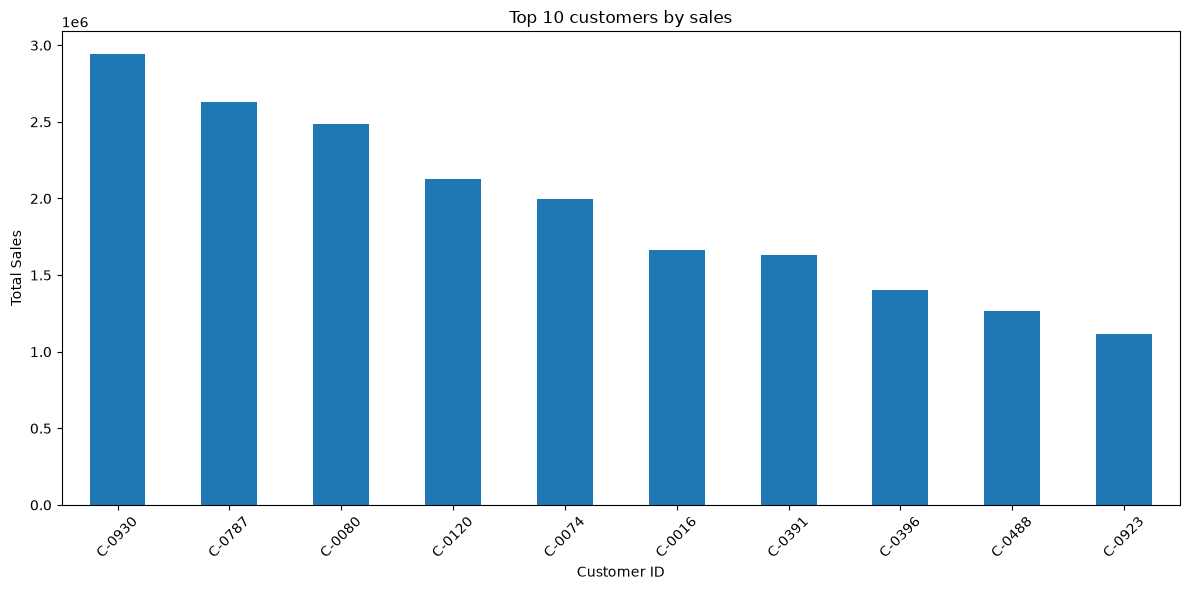

In [64]:
#Customer Analysis Visualizations

# Top 10 customers
plt.figure(figsize=(12,6))
top_10_customers.plot(kind="bar")

plt.title("Top 10 customers by sales")
plt.xlabel("Customer ID")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

It identifies the customers who generate the highest revenue for the company.


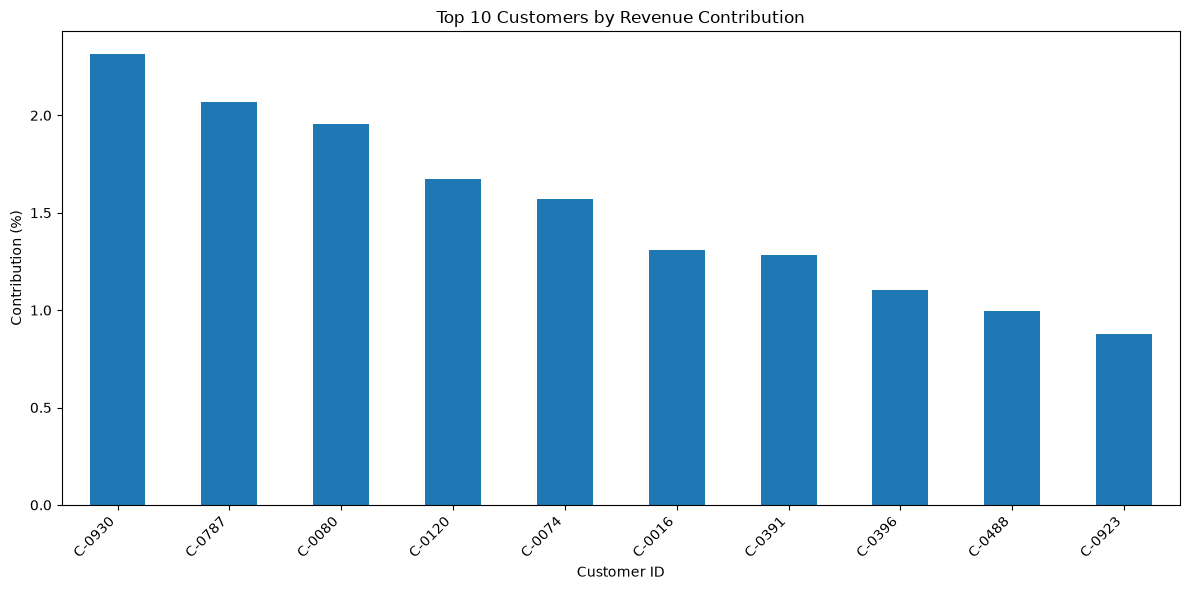

In [68]:
#Visualize the percentage contribution of the top 10 customers to total sales.
top_10_contribution = customer_contribution.sort_values(ascending=False).head(10)
plt.figure(figsize=(12,6))
top_10_contribution.plot(kind="bar")

plt.title("Top 10 Customers by Revenue Contribution")
plt.xlabel("Customer ID")
plt.ylabel("Contribution (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

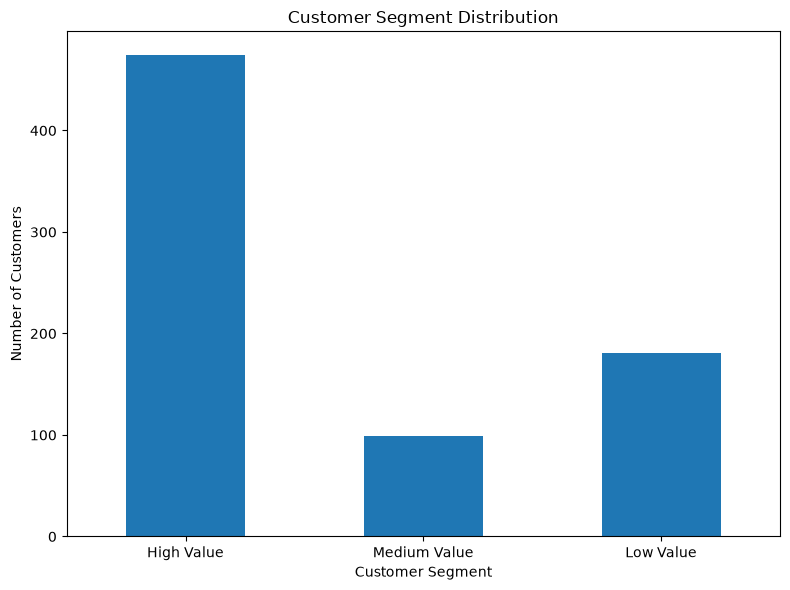

In [69]:
#Show how many customers belong to each segment: High Value, Medium Value, and Low Value.
plt.figure(figsize=(8, 6))

customer_segments.value_counts().reindex(
    ["High Value", "Medium Value", "Low Value"]
).plot(kind="bar")

plt.title("Customer Segment Distribution")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



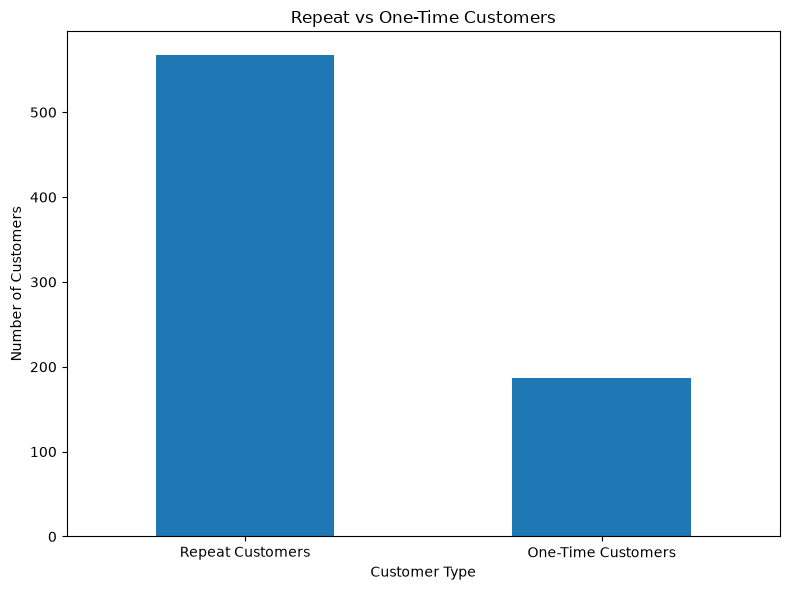

In [70]:
#Compare customers who placed multiple orders with customers who placed only one order
repeat_customer_count = (order_per_customer > 1).sum()
one_time_customer_count = (order_per_customer == 1).sum()

customer_type = pd.Series({
    "Repeat Customers": repeat_customer_count,
    "One-Time Customers": one_time_customer_count
})

plt.figure(figsize=(8,6))
customer_type.plot(kind="bar")

plt.title("Repeat vs One-Time Customers")
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
